# Solar filament segmentation: full pipeline demo

Solution to the *Solar Filament Segmentation Challenge 2026* (MAGFiLO, GONG H-alpha). The notebook runs the
**entire inference pipeline** with the stored weights: detector ensemble on dihedral test-time views, instance
voting, post-processing and export of the competition CSV (about 14 s per image on an Apple M4 Max, i.e. about 45 minutes for the 180 test images). Only the pixels of each test image are used
(no file-name metadata, no neighbouring frames, no external annotations).

Set `TEST_DIR` to the folder with the 180 test JPEGs. `LIMIT=None` processes all images; use a small number for a
smoke test. A GPU (CUDA or Apple MPS) is used automatically; on CPU the full run is slow.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

import torch, ultralytics
from filament_seg.pipeline import FilamentPipeline, PipelineConfig
from filament_seg.infer import load_gray_rgb
from filament_seg.rle import decode, read_instances

TEST_DIR = REPO / "data" / "MAGFiLO_1.0_Kaggle_2026" / "test" / "test_images"   # edit if needed
OUT_CSV = REPO / "submission.csv"
CONFIG_NAME = "final.json"   # "second.json" = the all-data refit pair (second selected submission)
LIMIT = None            # e.g. 3 for a quick smoke test
print("torch", torch.__version__, "| ultralytics", ultralytics.__version__)

torch 2.14.0 | ultralytics 8.4.138


In [2]:
cfg = json.loads((REPO / "configs" / CONFIG_NAME).read_text())
cfg["weights"] = [REPO / w for w in cfg["weights"]]
config = PipelineConfig(**cfg)
pipeline = FilamentPipeline(config)
print("device:", pipeline.device, "| detectors:", len(config.weights), "| views:", len(config.view_indices))
print({k: v for k, v in cfg.items() if k != "weights"})

device: mps | detectors: 6 | views: 8
{'imgsz': 2048, 'view_indices': [0, 1, 2, 3, 4, 5, 6, 7], 'conf': 0.03, 'iou': 0.0, 'max_det': 100, 'cluster_iou': 0.3, 'vote': 0.5, 'threshold': 0.18, 'erosion': 3, 'largest_component': True}


## Pipeline

1. **Detector** (YOLO11s-seg, COCO-pretrained, trained on the provided training annotations only): every annotator copy is a separate training example, split by physical observation.
2. **Test-time views**: each detector runs on the 8 dihedral views (4 rotations x flip) of the 2048x2048 image; masks are mapped back to the original frame.
3. **Instance voting**: instances of all (detector, view) sources are clustered by IoU > 0.3 with at most one member per source. The fused mask is the pixel vote of the members; the score is the sum of member confidences divided by the number of sources.
4. **Decision and clean-up**: contested pixels go to the higher score, instances below the score threshold are dropped, masks are eroded with a 3x3 ellipse (the annotators draw tighter outlines than the detector's quarter-resolution masks) and reduced to their largest connected component.
5. **Export**: COCO RLE `counts`, one row per instance.

20110120105534Ch.jpeg | sources: 48 | raw instances in the first source: 6 | one detector, one view: 4 | fused: 2


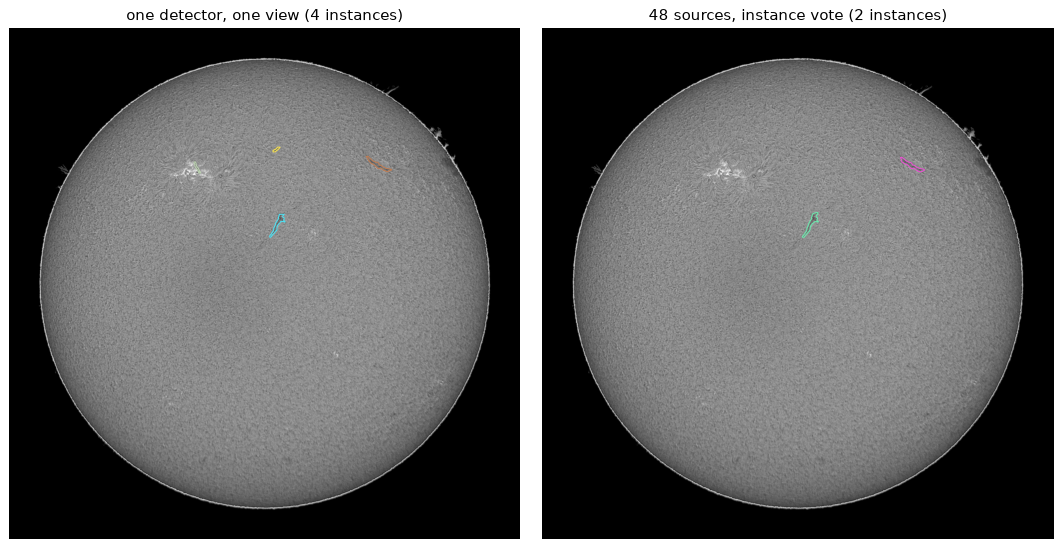

In [3]:
paths = sorted(TEST_DIR.glob("*.jp*g"))
image = load_gray_rgb(paths[0])
sources = pipeline.sources(image)          # every detector on every dihedral view, mapped back to the image frame
single = pipeline.finalize(sources[:1])    # first detector, identity view, same threshold / erosion / clean-up
final = pipeline.finalize(sources)         # instance vote over all sources
print(paths[0].name, "| sources:", len(sources), "| raw instances in the first source:", len(sources[0]),
      "| one detector, one view:", len(single), "| fused:", len(final))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
panels = ((f"one detector, one view ({len(single)} instances)", single), (f"{len(sources)} sources, instance vote ({len(final)} instances)", final))
rng = np.random.default_rng(0)
for ax, (title, rles) in zip(axes, panels):
    ax.imshow(image[..., 0], cmap="gray"); ax.set_title(title); ax.axis("off")
    for rle in rles:
        ax.contour(decode(rle), levels=[0.5], colors=[rng.uniform(0.3, 1, 3)], linewidths=0.8)
plt.tight_layout(); plt.show()

## Predict the whole test set and write the competition CSV

In [4]:
started = time.time()
rows = pipeline.predict_directory(TEST_DIR, OUT_CSV, limit=LIMIT)
print(f"{rows} instances written to {OUT_CSV} in {time.time() - started:.0f} s")

1/3 20110120105534Ch.jpeg: 2 instances
2/3 20110130110334Ch.jpeg: 1 instances
3/3 20110214175414Mh.jpeg: 3 instances
6 instances written to ./submission.csv in 27 s


In [5]:
pred = read_instances(OUT_CSV)
ids = [f"{o}_{i}" for o, rles in pred.items() for i in range(1, len(rles) + 1)]
assert len(ids) == len(set(ids)), "filament_id must be unique"
assert all(decode(r).any() for rles in pred.values() for r in rles), "empty mask found"
expected = {p.stem for p in sorted(TEST_DIR.glob("*.jp*g"))[:LIMIT]}
print("images with at least one instance:", len(pred), "of", len(expected), "| missing:", sorted(expected - set(pred))[:5])

images with at least one instance: 3 of 3 | missing: []


## Optional: score on the observation-grouped holdout

Needs the competition training data. `GT_CSV` holds the holdout annotator copies as `<annotator>-<observation>_<k>`
rows (`src/export_coco_ground_truth.py`); `HOLDOUT_PRED` is a CSV produced by the pipeline on the holdout images.

In [6]:
from filament_seg.metrics import bootstrap_pq, observation_parts, score_split, summarize
GT_CSV = REPO / "results" / "gt_holdout.csv"
HOLDOUT_PRED = REPO / "results" / "holdout_predictions.csv"
if GT_CSV.exists() and HOLDOUT_PRED.exists():
    scores = score_split(read_instances(GT_CSV), read_instances(HOLDOUT_PRED))
    summary = summarize(scores)
    _, parts = observation_parts(scores)
    print({k: round(v, 4) for k, v in summary.items()})
    print("PQ %.4f, 95%% CI [%.4f, %.4f]" % bootstrap_pq(parts))
    iou = np.concatenate([s.pair_iou for s in scores.values()]); dice = np.concatenate([s.pair_dice for s in scores.values()])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].hist(iou, bins=40); ax[0].set_title(f"IoU of overlapping pairs (mean {iou.mean():.3f})")
    ax[1].hist(dice, bins=40); ax[1].set_title(f"Dice of overlapping pairs (mean {dice.mean():.3f})")
    plt.tight_layout(); plt.show()
else:
    print("holdout files not found; skipping the optional evaluation")

holdout files not found; skipping the optional evaluation
